# 06. Đánh giá cuối trên tập test (Evaluation)

Notebook 05 đã **chốt** mô hình (LightGBM tinh chỉnh bằng Optuna, học trên toàn bộ dev, lưu ở `artifacts/best_model.joblib`) mà chưa hề thấy tập test. Notebook này mở tập test 20% (5.982 sản phẩm, thương hiệu không trùng với dev) **đúng một lần** để có con số khách quan.

**Quy tắc:** sau khi xem kết quả ở đây, không quay lại chỉnh mô hình, tham số hay đặc trưng. Nếu chỉnh, tập test không còn "chưa thấy" và con số sẽ lạc quan.

| Mục | Nội dung |
|---|---|
| 8.7 | Mở tập test, kiểm tra đúng tập đã khóa |
| 8.8 | Chỉ số trên test, so với đường cơ sở và với dev |
| 8.9 | Khoảng tin cậy 95% (bootstrap theo thương hiệu) |
| 8.10 | Ma trận nhầm lẫn, mức sai lệch |
| 8.11 | Theo thị trường và theo nhóm sản phẩm |
| 8.12 | Kiểm tra độ nhạy: bỏ sản phẩm có "bản sao" ở dev |
| 8.13 | Độ tin cậy của xác suất (calibration) |
| 8.14 | Ablation trên test: nhóm đặc trưng nào quan trọng, NOVA thêm bao nhiêu |
| 8.15 | Giải thích mô hình: thẻ nào kéo hạng xuống D/E, giải thích từng sản phẩm |
| 8.16 | Phân tích lỗi: vì sao mô hình sai |
| 8.17 | Trả lời câu hỏi nghiên cứu, so với tiêu chí thành công; lưu kết quả |

Thời gian chạy khoảng 5 phút. Tập test được mở lúc 2026-11-07 22:57 (ghi trong `reports/test_results.json`).

In [1]:
# Chạy từ thư mục gốc dự án để đọc được data/, sql/ và import src/
import os, sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
GRADE_COLORS = {"a": "#038141", "b": "#85BB2F", "c": "#FECB02", "d": "#EE8100", "e": "#E63E11"}
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

import json, time, joblib, sklearn, lightgbm
from scipy import sparse
from sklearn.metrics import classification_report, cohen_kappa_score, confusion_matrix, f1_score
from src.cleaning import as_list, normalize_name
from src.features import GROUPS, feature_names
from src.modeling import GRADES, check_split, fingerprint, make_model, metrics, select_dev, select_test

X = pd.read_parquet("data/final/clean_features.parquet")
y = pd.read_parquet("data/final/clean_labels.parquet")["nutriscore_grade"]
split = pd.read_parquet("data/final/split.parquet")
assert fingerprint(split) == "2e511eab89b680b7" and check_split(split)   # đúng tập test đã khóa ở Bước 7
X_dev, y_dev, split_dev = select_dev(X, y, split)

artifact = joblib.load("artifacts/best_model.joblib")
model = artifact["model"]
assert list(model.classes_) == GRADES
print("Mô hình:", artifact["name"], "|", artifact["trained_on"])
print("Tham số:", artifact["params"])
now = {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__, "pandas": pd.__version__,
       "python": sys.version.split()[0]}
print("Cùng phiên bản thư viện với lúc lưu mô hình:", artifact["versions"] == now, now)

Mô hình: LightGBM (Optuna) | dev (23922 dòng); tập test chưa mở
Tham số: {'n_estimators': 450, 'learning_rate': 0.023696519795929575, 'num_leaves': 187, 'min_child_samples': 3, 'colsample_bytree': 0.6453950698667689, 'subsample': 0.9244648639872316, 'reg_lambda': 1.726268877888677, 'subsample_freq': 1}
Cùng phiên bản thư viện với lúc lưu mô hình: True {'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'pandas': '3.0.6', 'python': '3.11.9'}


## 8.7. Mở tập test
`select_test(..., final=True)` là cách duy nhất lấy được tập test (notebook 01–05 không gọi được). Kiểm tra lại: không thương hiệu nào nằm ở cả dev và test; tỷ lệ các hạng ở test giống dev (vì chia có phân tầng).

In [2]:
X_test, y_test, split_test = select_test(X, y, split, final=True)   # MỞ TẬP TEST (chỉ ở notebook này)
print("Test:", X_test.shape, "| số nhóm (thương hiệu):", split_test["group_id"].nunique())
print("Không nhóm nào ở cả dev và test:", not set(split_dev["group_id"]) & set(split_test["group_id"]))
pd.DataFrame({"dev": pd.Series(y_dev).value_counts(normalize=True),
              "test": pd.Series(y_test).value_counts(normalize=True)}).loc[GRADES].round(3).T

Test: (5982, 27) | số nhóm (thương hiệu): 3053
Không nhóm nào ở cả dev và test: True


,a,b,c,d,e
dev,0.151,0.11,0.217,0.238,0.284
test,0.151,0.11,0.217,0.238,0.284


## 8.8. Kết quả trên test
Hai đường cơ sở cũng học trên toàn bộ dev rồi đo trên test, để so cùng điều kiện.

In [3]:
pred = model.predict(X_test)
proba = model.predict_proba(X_test)
baselines = {"Đường cơ sở: hạng phổ biến nhất": make_model("majority").fit(X_dev, y_dev),
             "Đường cơ sở: theo pnns_groups_2": make_model("category").fit(X_dev, y_dev)}
test_rows = {n: metrics(y_test, b.predict(X_test), b.predict_proba(X_test)) for n, b in baselines.items()}
test_rows[artifact["name"]] = metrics(y_test, pred, proba)
pd.DataFrame(test_rows).T

,macro_f1,accuracy,precision,recall,qwk,within_one,roc_auc,log_loss
Đường cơ sở: hạng phổ biến nhất,0.0885,0.2842,0.0568,0.2000,0.0000,0.5221,0.5000,1.5590
Đường cơ sở: theo pnns_groups_2,0.4137,0.4612,0.4495,0.4247,0.4623,0.7330,0.7582,1.2695
LightGBM (Optuna),0.6349,0.6506,0.6322,0.6386,0.7581,0.8847,0.8937,0.8813


In [4]:
# So với kết quả đánh giá chéo 5 fold trên dev (notebook 05)
dev_vs_test = pd.DataFrame({"dev (5 fold)": pd.Series(artifact["cv_dev"]), "test": pd.Series(test_rows[artifact["name"]])})
dev_vs_test["test - dev"] = dev_vs_test["test"] - dev_vs_test["dev (5 fold)"]
dev_vs_test.round(3)

,dev (5 fold),test,test - dev
macro_f1,0.625,0.635,0.010
accuracy,0.643,0.651,0.007
precision,0.627,0.632,0.005
recall,0.623,0.639,0.015
qwk,0.768,0.758,-0.010
within_one,0.894,0.885,-0.009
roc_auc,0.887,0.894,0.007
log_loss,0.911,0.881,-0.030


- Mô hình đã chốt đạt **Macro-F1 0,635, QWK 0,758, accuracy 65,1%, ROC-AUC 0,894** trên 5.982 sản phẩm chưa từng thấy; 88,5% dự đoán lệch tối đa 1 hạng.
- Hơn đường cơ sở `pnns_groups_2` (Macro-F1 0,414, QWK 0,462 trên test) **+0,221 Macro-F1 và +0,296 QWK**. Hai đường cơ sở trên test gần bằng trên dev.
- **Chênh với dev rất nhỏ** (Macro-F1 +0,010, QWK −0,010), cỡ dao động giữa các fold: chọn tham số trên dev không làm điểm lạc quan đáng kể, và chia theo thương hiệu cho ước lượng đáng tin.

## 8.9. Khoảng tin cậy 95% (bootstrap)
Một con số trên 5.982 sản phẩm vẫn có sai số do mẫu. **Bootstrap**: rút lại ngẫu nhiên có hoàn lại 1.000 lần rồi xem chỉ số dao động trong khoảng nào. Rút theo **thương hiệu** (cả nhóm sản phẩm cùng hãng đi cùng nhau), vì sản phẩm cùng hãng giống nhau, rút từng dòng sẽ cho khoảng hẹp hơn thực tế.

Dòng cuối là khoảng tin cậy của **chênh lệch** Macro-F1 giữa mô hình và đường cơ sở `pnns_groups_2` trên cùng mẫu rút: nếu cả khoảng lớn hơn 0 thì mô hình hơn đường cơ sở một cách chắc chắn, không phải do may mắn.

In [5]:
t = np.array([GRADES.index(g) for g in y_test])
p = np.array([GRADES.index(g) for g in pred])
b = np.array([GRADES.index(g) for g in baselines["Đường cơ sở: theo pnns_groups_2"].predict(X_test)])
rows_of_group = list(pd.Series(np.arange(len(t))).groupby(split_test["group_id"].to_numpy()).indices.values())

def scores(ix):
    f1 = lambda a: f1_score(t[ix], a[ix], labels=range(5), average="macro", zero_division=0)
    return {"macro_f1": f1(p), "qwk": cohen_kappa_score(t[ix], p[ix], weights="quadratic", labels=list(range(5))),
            "accuracy": np.mean(t[ix] == p[ix]), "within_one": np.mean(np.abs(t[ix] - p[ix]) <= 1),
            "Macro-F1 hơn đường cơ sở": f1(p) - f1(b)}

rng = np.random.default_rng(42)
boot = []
for _ in range(1000):
    pick = rng.integers(0, len(rows_of_group), len(rows_of_group))      # rút thương hiệu có hoàn lại
    boot.append(scores(np.concatenate([rows_of_group[i] for i in pick])))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"trên test": pd.Series(scores(np.arange(len(t)))),
                   "2,5%": boot.quantile(0.025), "97,5%": boot.quantile(0.975)}).round(3)
ci

,trên test,"2,5%","97,5%"
macro_f1,0.635,0.616,0.652
qwk,0.758,0.724,0.788
accuracy,0.651,0.631,0.670
within_one,0.885,0.870,0.898
Macro-F1 hơn đường cơ sở,0.221,0.202,0.240


- Macro-F1 nằm trong khoảng **0,616–0,652**, QWK **0,724–0,788** (95%). Điểm dev 0,625 nằm trong khoảng này.
- Mô hình hơn đường cơ sở 0,202–0,240 Macro-F1: cả khoảng lớn hơn 0 nên chênh lệch là chắc chắn, không phải do mẫu may mắn.

## 8.10. Ma trận nhầm lẫn và mức sai lệch

              precision    recall  f1-score   support

           a      0.718     0.743     0.731       903
           b      0.472     0.528     0.498       659
           c      0.588     0.567     0.577      1297
           d      0.630     0.598     0.614      1423
           e      0.754     0.757     0.755      1700

    accuracy                          0.651      5982
   macro avg      0.632     0.639     0.635      5982
weighted avg      0.652     0.651     0.651      5982



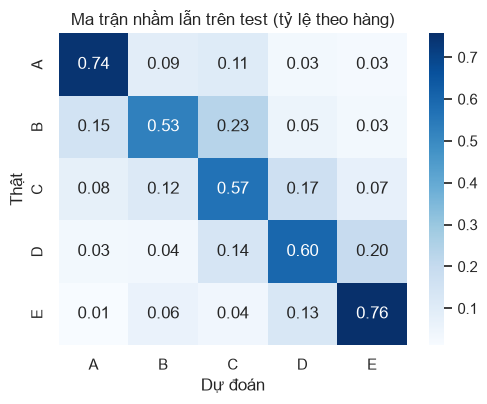

{'lệch 0 hạng': 0.651, 'lệch 1 hạng': 0.234, 'lệch 2 hạng': 0.075, 'lệch 3 hạng': 0.033, 'lệch 4 hạng': 0.007}
A thật bị đoán D/E: 52 | E thật bị đoán A/B: 126


In [6]:
print(classification_report(y_test, pred, labels=GRADES, digits=3))
cm = confusion_matrix(y_test, pred, labels=GRADES, normalize="true")
plt.figure(figsize=(5.2, 4.2))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=[g.upper() for g in GRADES],
            yticklabels=[g.upper() for g in GRADES])
plt.xlabel("Dự đoán"); plt.ylabel("Thật"); plt.title("Ma trận nhầm lẫn trên test (tỷ lệ theo hàng)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_01_ma_tran_nham_lan_test.png", dpi=110); plt.show()

gap = pd.Series(np.abs(t - p)).value_counts(normalize=True).sort_index()
gap.index = [f"lệch {k} hạng" for k in gap.index]
print(gap.round(3).to_dict())
print("A thật bị đoán D/E:", int(((t == 0) & (p >= 3)).sum()), "| E thật bị đoán A/B:", int(((t == 4) & (p <= 1)).sum()))

- F1 từng hạng giống dev: E (0,755) và A (0,731) dễ nhất; **B khó nhất (0,498)**: ít mẫu, bị kẹp giữa A và C, và theo công thức 2023 hạng B chỉ rộng 2 điểm Nutri-Score (1–2).
- 65,1% đúng, 23,4% lệch 1 hạng, 7,5% lệch 2 hạng, 4,0% lệch 3–4 hạng. Sai xa hiếm: 52 sản phẩm A bị đoán D/E và 126 sản phẩm E bị đoán A/B (3,0% tập test).

## 8.11. Theo thị trường và theo nhóm sản phẩm
So với cùng nhóm trên dev (dự đoán ngoài fold của notebook 05) để xem mức khó có giữ nguyên không.

In [7]:
oof = pd.read_parquet("data/processed/oof_predictions.parquet")
assert (oof["row_id"].to_numpy() == X_dev["row_id"].to_numpy()).all()

def has_country(Xp, tag):
    return Xp["countries_tags"].map(lambda v: tag in (as_list(v) or [])).to_numpy()

def markets(Xp):
    fr, us = has_country(Xp, "en:france"), has_country(Xp, "en:united-states")
    return {"Bán ở Pháp": fr, "Bán ở Mỹ": us, "Còn lại": ~fr & ~us}

dev_m = markets(X_dev)
by_market = pd.DataFrame([{"thị trường": name, "số dòng test": int(m.sum()),
                           "Macro-F1 test": metrics(y_test[m], pred[m])["macro_f1"],
                           "Macro-F1 dev": metrics(oof["y_true"][dev_m[name]], oof["y_pred"][dev_m[name]])["macro_f1"]}
                          for name, m in markets(X_test).items()])
by_market

,thị trường,số dòng test,Macro-F1 test,Macro-F1 dev
0,Bán ở Pháp,1754,0.6828,0.6498
1,Bán ở Mỹ,2266,0.6097,0.6222
2,Còn lại,1985,0.6168,0.6056


In [8]:
g_test = X_test["pnns_groups_1"].fillna("missing").to_numpy()
g_dev = X_dev["pnns_groups_1"].fillna("missing").to_numpy()
rows = []
for g in pd.unique(g_test):
    m = g_test == g
    if m.sum() >= 100:
        r = metrics(y_test[m], pred[m])
        rows.append({"nhóm pnns_groups_1": g, "số dòng test": int(m.sum()), "Macro-F1 test": r["macro_f1"],
                     "accuracy test": r["accuracy"], "lệch ≤ 1 hạng": r["within_one"],
                     "Macro-F1 dev": metrics(oof["y_true"][g_dev == g], oof["y_pred"][g_dev == g])["macro_f1"]})
by_group = pd.DataFrame(rows).sort_values("Macro-F1 test")
by_group.round(3)

,nhóm pnns_groups_1,số dòng test,Macro-F1 test,accuracy test,lệch ≤ 1 hạng,Macro-F1 dev
3,composite foods,392,0.458,0.566,0.862,0.421
1,missing,1167,0.488,0.549,0.823,0.507
5,sugary snacks,989,0.528,0.804,0.971,0.512
7,fish meat eggs,500,0.530,0.596,0.852,0.532
9,fruits and vegetables,332,0.576,0.696,0.882,0.569
6,fats and sauces,418,0.594,0.612,0.873,0.592
0,salty snacks,220,0.599,0.623,0.954,0.514
8,beverages,660,0.603,0.603,0.811,0.666
4,cereals and potatoes,722,0.626,0.668,0.911,0.589
2,milk and dairy products,582,0.678,0.742,0.940,0.601


- **Thị trường:** Pháp 0,683 cao nhất (dữ liệu Pháp đầy đủ, thẻ danh mục chi tiết); Mỹ 0,610 và nước khác 0,617, gần như dev.
- **Nhóm khó nhất** (câu hỏi 1): món ăn hỗn hợp (0,458) và sản phẩm thiếu nhóm (0,488), giống dev. Bánh kẹo ngọt Macro-F1 chỉ 0,528 dù accuracy 80%: phần lớn là E nên đoán E đúng nhiều, nhưng các sản phẩm C/D trong nhóm này hay bị đoán E (xem 8.16).
- Đồ uống giảm từ 0,666 (dev) xuống 0,603 (test): đồ uống có thang điểm riêng và hạng phụ thuộc lượng đường, nên dao động theo mẫu. Sữa và chế phẩm sữa dễ nhất (0,678).

## 8.12. Kiểm tra độ nhạy: sản phẩm có "bản sao" ở dev
Chia theo thương hiệu bảo đảm không hãng nào nằm ở cả hai phía. Nhưng nhiều sản phẩm phổ thông của **các hãng khác nhau** có cùng tên và cùng thành phần (sữa ít béo, dầu ô liu, nước khoáng). Đây là dữ liệu thật, không phải lỗi chia. Tuy vậy, cần chắc điểm test không nhờ chúng mà cao lên: tính lại sau khi bỏ những sản phẩm test có cùng (tên chuẩn hóa + thành phần) hoặc cùng (thành phần + danh mục, ít nhất 3 thành phần) với một sản phẩm dev.

In [9]:
def join_tags(v, sort=False):
    tags = [str(x) for x in (as_list(v) or [])]
    return "|".join(sorted(tags) if sort else tags)

def keys(Xp):
    name = Xp["product_name"].fillna("").map(normalize_name)
    ing = Xp["ingredients_tags"].map(join_tags)
    by_name = (name + "#" + ing).where(name.ne(""))
    by_recipe = (ing + "#" + Xp["categories_tags"].map(lambda v: join_tags(v, sort=True))).where(
        Xp["ingredients_tags"].map(lambda v: len(as_list(v) or [])) >= 3)
    return by_name, by_recipe

dev_name, dev_recipe = keys(X_dev)
test_name, test_recipe = keys(X_test)
twin = (test_name.isin(set(dev_name.dropna())) | test_recipe.isin(set(dev_recipe.dropna()))).to_numpy()
sensitivity = pd.DataFrame({name: {"số dòng": int(m.sum()), **metrics(y_test[m], pred[m])}
                            for name, m in {"toàn bộ test": np.ones(len(t), bool), "bỏ sản phẩm có bản sao": ~twin,
                                            "chỉ sản phẩm có bản sao": twin}.items()}).T
sensitivity[["số dòng", "macro_f1", "qwk", "accuracy"]].round(3)

,số dòng,macro_f1,qwk,accuracy
toàn bộ test,5982.0,0.635,0.758,0.651
bỏ sản phẩm có bản sao,5708.0,0.621,0.744,0.639
chỉ sản phẩm có bản sao,274.0,0.883,0.955,0.898


274 sản phẩm test (4,6%) có bản sao ở dev; trên nhóm này mô hình đúng 89,8% (Macro-F1 0,883), dễ hơn hẳn. Bỏ chúng đi, Macro-F1 còn **0,621** và QWK 0,744: giảm 0,014 nhưng vẫn vượt xa đường cơ sở và gần bằng dev. Điểm test không bị thổi phồng đáng kể; con số thận trọng để báo cáo là **0,62–0,635**.

## 8.13. Xác suất của mô hình có đáng tin không? (calibration)
Mô hình cho mỗi sản phẩm một xác suất cho hạng dự đoán ("độ tự tin"). Nếu xác suất **đáng tin**, thì trong các sản phẩm mô hình tự tin 70%, khoảng 70% phải đúng. Biểu đồ dưới chia sản phẩm theo độ tự tin; điểm càng gần đường chéo càng tốt. ECE (expected calibration error) = chênh trung bình giữa độ tự tin và tỷ lệ đúng.

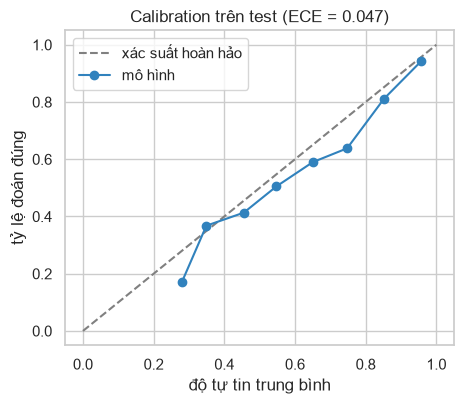

Tự tin ≥ 80%: 36.5% sản phẩm, đúng 89.2% | tự tin < 50%: 21.4% sản phẩm, đúng 38.2%


,so_dong,do_tu_tin,ty_le_dung
bin,,,
0,82,0.280,0.171
1,454,0.349,0.368
2,745,0.455,0.413
3,855,0.548,0.505
4,807,0.650,0.590
5,854,0.748,0.638
6,833,0.852,0.812
7,1352,0.957,0.942


In [10]:
conf = proba.max(axis=1)
correct = pred == y_test
bins = np.digitize(conf, np.linspace(0.2, 1.0, 9)[1:-1])
cal = pd.DataFrame({"conf": conf, "correct": correct, "bin": bins}).groupby("bin").agg(
    so_dong=("conf", "size"), do_tu_tin=("conf", "mean"), ty_le_dung=("correct", "mean"))
ece = float((cal["so_dong"] / len(conf) * (cal["do_tu_tin"] - cal["ty_le_dung"]).abs()).sum())

plt.figure(figsize=(4.8, 4.2))
plt.plot([0, 1], [0, 1], "--", color="grey", label="xác suất hoàn hảo")
plt.plot(cal["do_tu_tin"], cal["ty_le_dung"], "o-", color="#3182bd", label="mô hình")
plt.xlabel("độ tự tin trung bình"); plt.ylabel("tỷ lệ đoán đúng"); plt.title(f"Calibration trên test (ECE = {ece:.3f})")
plt.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "eval_02_hieu_chinh.png", dpi=110); plt.show()

high = conf >= 0.8
print(f"Tự tin ≥ 80%: {high.mean():.1%} sản phẩm, đúng {correct[high].mean():.1%} | "
      f"tự tin < 50%: {(conf < 0.5).mean():.1%} sản phẩm, đúng {correct[conf < 0.5].mean():.1%}")
cal.round(3)

ECE = 0,047: xác suất khá đáng tin nhưng **hơi tự tin quá** ở khoảng giữa (tự tin 75% thì đúng 64%). Dùng thực tế: 36,5% sản phẩm được đoán với độ tự tin ≥ 80% và đúng 89,2%; 21,4% sản phẩm có độ tự tin < 50% chỉ đúng 38,2%. Dashboard nên hiện xác suất và cảnh báo khi độ tự tin thấp.

## 8.14. Ablation trên test (câu hỏi nghiên cứu 3)
Notebook 05 đã làm ablation bằng đánh giá chéo trên dev. Ở đây kiểm tra lại các cấu hình chính trên test: học mô hình **cùng tham số** nhưng bỏ bớt nhóm đặc trưng, trên toàn bộ dev, rồi đo trên test. Đây chỉ là phân tích; mô hình đã chốt vẫn là bản đủ nhóm, không chọn lại dựa trên bảng này.

In [11]:
configs = {"đủ nhóm (mô hình đã chốt)": None,
           "chỉ thành phần (ingredients + position)": ["ingredients", "position"],
           "thành phần + NOVA": ["ingredients", "position", "nova"],
           "bỏ categories": [g for g in GROUPS if g != "categories"],
           "bỏ ingredients": [g for g in GROUPS if g != "ingredients"],
           "bỏ nova": [g for g in GROUPS if g != "nova"]}
dev_ablation = {r["cấu hình"]: r["Macro-F1"] for r in json.loads(Path("reports/model_results.json").read_text(encoding="utf-8"))["ablation"]}
start, rows = time.time(), []
for name, groups in configs.items():
    m = model if groups is None else make_model("lgbm", groups=groups, **artifact["params"]).fit(X_dev, y_dev)
    r = metrics(y_test, m.predict(X_test))
    rows.append({"cấu hình": name, "Macro-F1 test": r["macro_f1"], "QWK test": r["qwk"],
                 "Macro-F1 dev": dev_ablation.get(name, artifact["cv_dev"]["macro_f1"])})
ablation_test = pd.DataFrame(rows)
ablation_test["thay đổi trên test"] = ablation_test["Macro-F1 test"] - ablation_test.loc[0, "Macro-F1 test"]
print(f"{(time.time() - start) / 60:.1f} phút")
ablation_test.round(3)

1.0 phút


,cấu hình,Macro-F1 test,QWK test,Macro-F1 dev,thay đổi trên test
0,đủ nhóm (mô hình đã chốt),0.635,0.758,0.625,0.000
1,chỉ thành phần (ingredients + position),0.567,0.657,0.557,-0.068
2,thành phần + NOVA,0.568,0.664,0.559,-0.067
3,bỏ categories,0.580,0.685,0.566,-0.054
4,bỏ ingredients,0.603,0.721,0.593,-0.032
5,bỏ nova,0.634,0.756,0.624,-0.001


Test lặp lại đúng thứ tự của dev (câu hỏi 3):
- **Danh mục quan trọng nhất**: bỏ đi giảm 0,054 (dev 0,058); **thành phần** thứ hai: giảm 0,032 (dev 0,032).
- Chỉ thành phần đạt 0,567; thêm NOVA đạt 0,568 (**+0,001**); bỏ NOVA khỏi mô hình đủ nhóm giảm 0,001. NOVA gần như không thêm thông tin khi đã có thành phần, vì NOVA được suy ra từ chính danh sách thành phần và phụ gia.

## 8.15. Giải thích mô hình (câu hỏi nghiên cứu 2)

**Vì sao không dùng SHAP?** SHAP chia điểm dự đoán của mô hình thành phần đóng góp của từng đặc trưng; tính chất cơ bản là **tổng các phần đóng góp phải bằng điểm của mô hình**. LightGBM có sẵn cách tính SHAP (`pred_contrib=True`), nhưng ô dưới cho thấy với mô hình này tổng **không** khớp: Optuna chọn `num_leaves` 187 và `min_child_samples` 3 nên cây rất sâu (trung vị 39 tầng, sâu nhất 76), và thuật toán TreeSHAP mất chính xác số học trên các nhánh quá dài: tổng lệch tới 7,1 (thang log-odds) so với điểm thật. Giá trị SHAP sai thì giải thích cũng sai, nên ta không dùng.

**Cách thay thế: "tắt thẻ".** Với một sản phẩm có thẻ X (ví dụ `en:sugar`), đặt cột X về 0 rồi dự đoán lại; chênh xác suất chính là ảnh hưởng của X lên dự đoán của sản phẩm đó. Cách này dùng đúng mô hình đã chốt, không xấp xỉ, và dễ kiểm tra bằng tay.

In [12]:
clf, feat = model["model"], model["features"]
M_test = feat.transform(X_test).tocsr()
names = np.array(feature_names(feat))
part = np.array([n.split("__")[0] for n in names])

sample = M_test[:50]
contrib = np.stack([c.toarray() for c in clf.booster_.predict(sample, pred_contrib=True)], axis=1)  # (50, 5 hạng, cột + hệ số chặn)
raw = clf.booster_.predict(sample, raw_score=True)
print("Sai lệch lớn nhất giữa tổng SHAP và điểm của mô hình:", round(float(np.abs(contrib.sum(-1) - raw).max()), 3))

def depth(node):
    return 0 if "split_index" not in node else 1 + max(depth(node["left_child"]), depth(node["right_child"]))
depths = [depth(tree["tree_structure"]) for tree in clf.booster_.dump_model()["tree_info"]]
print(f"{len(depths)} cây, độ sâu trung vị {int(np.median(depths))}, sâu nhất {max(depths)}")

Sai lệch lớn nhất giữa tổng SHAP và điểm của mô hình: 7.124


2250 cây, độ sâu trung vị 39, sâu nhất 76


In [13]:
TAG_PARTS = {"ingredients": "thành phần", "first": "đứng đầu", "additives": "phụ gia", "categories": "danh mục",
             "labels": "nhãn", "analysis": "phân tích", "countries": "quốc gia"}
DE = [GRADES.index("d"), GRADES.index("e")]
p_de = clf.predict_proba(M_test)[:, DE].sum(axis=1)       # xác suất D hoặc E của từng sản phẩm test

def without(M, cols):
    '''Bản sao của ma trận M với các cột `cols` đặt về 0 ("tắt thẻ").'''
    mask = np.ones(M.shape[1]); mask[cols] = 0
    out = sparse.csr_matrix(M.multiply(mask)); out.eliminate_zeros()
    return out

def pretty(name):
    p_, tag = name.split("__", 1)
    return f"{TAG_PARTS.get(p_, p_)}: {tag.replace('en:', '')}"

M_csc, rows = M_test.tocsc(), []
for j in np.flatnonzero(np.isin(part, ["ingredients", "additives"])):
    r = M_csc[:, j].nonzero()[0]
    if len(r) >= 30:
        p_off = clf.predict_proba(without(M_test[r], [j]))[:, DE].sum(axis=1)
        rows.append({"thẻ": pretty(names[j]), "số sản phẩm test có thẻ": len(r),
                     "P(D/E) tăng thêm nhờ thẻ": float((p_de[r] - p_off).mean())})
effect = pd.DataFrame(rows).sort_values("P(D/E) tăng thêm nhờ thẻ", ascending=False)
print(len(effect), "thẻ thành phần/phụ gia có ở ≥ 30 sản phẩm test")
effect.head(15).round(3)

584 thẻ thành phần/phụ gia có ở ≥ 30 sản phẩm test


,thẻ,số sản phẩm test có thẻ,P(D/E) tăng thêm nhờ thẻ
317,thành phần: olive,45,0.079
83,thành phần: coconut-oil,175,0.074
316,thành phần: oily-fish,80,0.064
348,thành phần: pineapple-juice,34,0.064
52,thành phần: cashew-nuts,75,0.052
146,thành phần: e252,46,0.051
255,thành phần: grape-juice,49,0.045
37,thành phần: butter,286,0.042
371,thành phần: raisin,69,0.037
378,thành phần: rennet,100,0.035


In [14]:
effect.tail(10).iloc[::-1].round(3)       # các thẻ kéo hạng LÊN (làm giảm xác suất D/E)

,thẻ,số sản phẩm test có thẻ,P(D/E) tăng thêm nhờ thẻ
387,thành phần: salad,40,-0.050
60,thành phần: chia,30,-0.047
258,thành phần: ham,44,-0.043
432,thành phần: sweetener,87,-0.039
494,thành phần: wholemeal-flour,116,-0.036
474,thành phần: water,2120,-0.035
34,thành phần: broth,80,-0.034
109,thành phần: cumin,60,-0.034
40,thành phần: cabbage,40,-0.033
23,thành phần: bay-leaf,40,-0.031


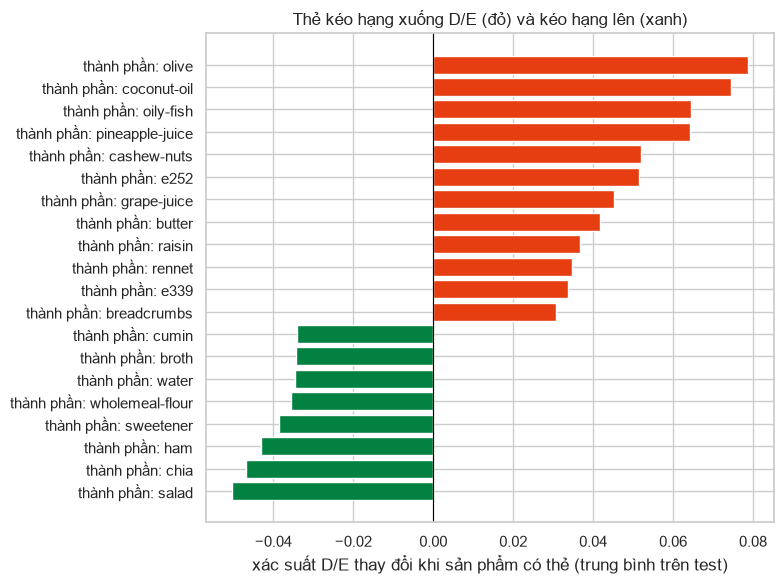

In [15]:
show = pd.concat([effect.head(12), effect.tail(8)]).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(show["thẻ"], show["P(D/E) tăng thêm nhờ thẻ"],
         color=np.where(show["P(D/E) tăng thêm nhờ thẻ"] > 0, GRADE_COLORS["e"], GRADE_COLORS["a"]))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("xác suất D/E thay đổi khi sản phẩm có thẻ (trung bình trên test)")
plt.title("Thẻ kéo hạng xuống D/E (đỏ) và kéo hạng lên (xanh)")
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_03_the_keo_hang.png", dpi=110); plt.show()

Kết luận câu hỏi 2 (ảnh hưởng trung bình khi sản phẩm có thẻ, tính trong bối cảnh danh mục và các thành phần khác của chính sản phẩm đó):
- **Kéo về D/E:** ô liu (+0,079, thường ngâm muối), **dầu dừa** (+0,074), cá nhiều dầu (+0,064), nước ép dứa/nho (+0,064/+0,045, đồ uống nhiều đường), hạt điều (+0,052), **E252 kali nitrat** (+0,051, chất bảo quản thịt nguội), **bơ** (+0,042), nho khô (+0,037), men đông tụ rennet (+0,035, phô mai), **E339 natri phosphat** (+0,034, phô mai chế biến, thịt). Điểm chung: nhiều chất béo bão hòa, muối hoặc đường.
- **Kéo lên:** rau trộn (−0,050), hạt chia (−0,047), giăm bông (−0,043), **chất tạo ngọt** (−0,039, đồ uống không đường), bột nguyên cám (−0,036), **nước** (−0,035, có ở 2.120 sản phẩm), nước dùng, thì là Ai Cập, bắp cải.
- Chỉ hai phụ gia (E252, E339) vào nhóm đầu, khớp với ablation: phụ gia nói chung không tự quyết định hạng mà đi cùng loại sản phẩm (thịt nguội, phô mai chế biến). Đây là ảnh hưởng **trong mô hình**, không phải quan hệ nhân quả.

**Giải thích từng sản phẩm.** Với một sản phẩm, tắt lần lượt từng thẻ nó có và xem xác suất của hạng được dự đoán giảm (thẻ ủng hộ hạng đó) hay tăng (thẻ chống lại). Đây cũng là phần giải thích sẽ dùng trong dashboard. Hai ví dụ: một sản phẩm bánh kẹo hạng E được đoán đúng (độ tự tin vừa phải, khoảng 75%) và sản phẩm bị đoán sai mà mô hình tự tin nhất.

đoán đúng | Easy cheese pasteurized cheese snack cheese 1x8.000 oz | biscuits and cakes | NOVA 4 | en:whey|en:dairy|en:canola-oil|en:oil-and-fat|en:vegetable-oil-and-fat|en:rapeseed-oil|en:milk-protein-concentrate|en:protein|en:animal-protein|en:milk-proteins|en:cheddar|en:cheese|en:milk|en:contain
sai mà tự tin nhất | Piasten, Chocolate Assortment | sweets | NOVA 4 | en:sugar|en:added-sugar|en:disaccharide|en:wheat-starch|en:starch|en:glucose-syrup|en:monosaccharide|en:glucose|en:soya|en:lactose|en:vegetable-fat|en:oil-and-fat|en:vegetable-oil-and-fat|en:cocoa-but


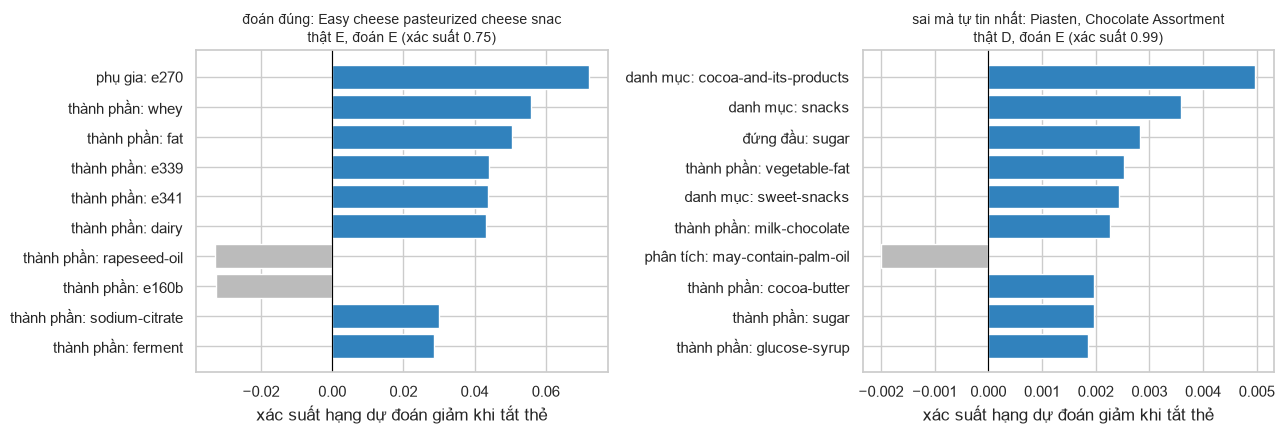

In [16]:
def explain(i, top=10):
    '''Ảnh hưởng của từng thẻ lên xác suất hạng dự đoán của sản phẩm thứ i trong tập test.'''
    k = GRADES.index(pred[i])
    cols = [j for j in M_test[i].indices if part[j] in TAG_PARTS]
    p_off = clf.predict_proba(sparse.vstack([without(M_test[i], [j]) for j in cols]))[:, k]
    s = pd.Series(proba[i, k] - p_off, index=[pretty(names[j]) for j in cols])
    return s.reindex(s.abs().sort_values(ascending=False).index).head(top)

# Ví dụ đoán đúng: bánh kẹo hạng E, độ tự tin gần 75% (khi xác suất đã gần 100%, tắt một thẻ gần như không đổi gì)
cand = np.flatnonzero(correct & (y_test == "e") & (X_test["pnns_groups_1"] == "sugary snacks").to_numpy(dtype=bool)
                      & (X_test["ingredients_n"].to_numpy(dtype=float) >= 5))
examples = {"đoán đúng": cand[np.argmin(np.abs(conf[cand] - 0.75))],
            "sai mà tự tin nhất": np.flatnonzero(~correct)[np.argmax(conf[~correct])]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (title, i) in zip(axes, examples.items()):
    s = explain(i)[::-1]
    ax.barh(s.index, s.values, color=np.where(s.values > 0, "#3182bd", "#bbbbbb"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{title}: {str(X_test['product_name'].iloc[i])[:35]}\nthật {y_test[i].upper()}, đoán {pred[i].upper()} "
                 f"(xác suất {conf[i]:.2f})", fontsize=10)
    ax.set_xlabel("xác suất hạng dự đoán giảm khi tắt thẻ")
    print(title, "|", X_test["product_name"].iloc[i], "|", X_test["pnns_groups_2"].iloc[i], "|",
          "NOVA", X_test["nova_group"].iloc[i], "|", join_tags(X_test["ingredients_tags"].iloc[i])[:200])
plt.tight_layout(); plt.savefig(FIG_DIR / "eval_04_giai_thich_vi_du.png", dpi=110); plt.show()

- **Đoán đúng (Easy Cheese, hạng E, tự tin 0,75):** axit lactic E270, whey, chất béo, muối phosphat E339/E341 đẩy về E; dầu cải và phẩm màu E160b kéo nhẹ ngược lại.
- **Sai tự tin nhất (Piasten Chocolate Assortment, thật D, đoán E với 0,99):** danh mục ca cao, snack ngọt, đường đứng đầu, sô cô la sữa, bơ ca cao: đúng chân dung một sản phẩm hạng E. Mỗi thẻ chỉ góp rất ít vì mô hình đã gần chắc chắn. Sản phẩm là hạng D (điểm 14) vì bảng dinh dưỡng ghi đường chỉ 6,5 g/100 g (thấp bất thường với sô cô la, có thể nhập sai): thông tin này mô hình không được thấy.

## 8.16. Phân tích lỗi: vì sao mô hình sai?
Để hiểu lỗi, ta lấy thêm **điểm Nutri-Score và bảng dinh dưỡng** của sản phẩm test từ `products.parquet`. Các cột này **chỉ dùng để phân tích lỗi**, không bao giờ đưa vào mô hình.

Mỗi lỗi được gán một nguyên nhân (xét theo thứ tự, lấy nguyên nhân đầu tiên khớp):
1. **Dữ liệu nghi sai:** hạng không khớp điểm theo ngưỡng 2023 (trừ nước lọc hạng A và chất béo/hạt có ngưỡng riêng), hoặc dinh dưỡng phi lý (> 100 g/100 g, âm, > 900 kcal).
2. **Sát ranh giới:** đoán lệch 1 hạng và điểm thật cách ngưỡng giữa hai hạng ≤ 1,5 điểm. Ngưỡng (gần đúng, công thức 2023): thường A ≤ 0 < B ≤ 2 < C ≤ 10 < D ≤ 18 < E; đồ uống B ≤ 2 < C ≤ 6 < D ≤ 9 < E.
3. **Cùng công thức, khác hạng:** ở dev có sản phẩm cùng thành phần + danh mục mà hạng đúng bằng hạng mô hình đoán. Hai sản phẩm giống hệt về đầu vào nhưng khác lượng đường/muối/chất béo; mô hình không thể phân biệt.
4. **Thiếu thông tin:** ≤ 1 thành phần hoặc thiếu nhóm sản phẩm.
5. **Đồ uống:** dùng thang điểm riêng.
6. **Khác.**

In [17]:
products = pd.read_parquet("data/processed/products.parquet").set_index("row_id")
NUTRIENTS = ["nutriscore_score", "energy_kcal_100g", "sugars_100g", "saturated_fat_100g", "salt_100g", "fiber_100g"]
nut = products.loc[X_test["row_id"], NUTRIENTS].reset_index(drop=True)
bev = (X_test["pnns_groups_1"] == "beverages").to_numpy()
score = nut["nutriscore_score"].to_numpy()

CUTS = {False: [0.5, 2.5, 10.5, 18.5], True: [-np.inf, 2.5, 6.5, 9.5]}     # ngưỡng giữa A|B, B|C, C|D, D|E
grade_from_score = np.array([np.searchsorted(CUTS[bool(bv)], s) if not np.isnan(s) else -1 for s, bv in zip(score, bev)])
cut_between = np.array([CUTS[bool(bv)][min(a, c)] if abs(a - c) == 1 else np.nan for a, c, bv in zip(t, p, bev)])

fat = X_test["pnns_groups_2"].isin(["fats", "nuts"]).to_numpy()            # chất béo/hạt: ngưỡng riêng, không xét
mismatch = (grade_from_score != t) & ~(bev & (t == 0)) & ~fat              # nước lọc hạng A là quy tắc riêng
bad_data = mismatch | (nut[["sugars_100g", "saturated_fat_100g", "salt_100g", "fiber_100g"]] > 100).any(axis=1).to_numpy() \
           | (nut[NUTRIENTS[1:]] < 0).any(axis=1).to_numpy() | (nut["energy_kcal_100g"] > 900).to_numpy()
near_cut = np.abs(score - cut_between) <= 1.5
recipe_key = lambda Xp: Xp["ingredients_tags"].map(join_tags) + "#" + Xp["categories_tags"].map(lambda v: join_tags(v, sort=True))
dev_labels = pd.Series(y_dev).groupby(recipe_key(X_dev).to_numpy()).agg(set)        # các hạng ở dev của mỗi công thức
same_recipe = np.array([pred[i] in dev_labels.get(r, set()) for i, r in enumerate(recipe_key(X_test))])
little_info = ((X_test["ingredients_n"] <= 1) | X_test["pnns_groups_1"].isna()).to_numpy(dtype=bool)

cause = np.select([bad_data, near_cut, same_recipe, little_info, bev],
                  ["dữ liệu nghi sai", "sát ranh giới", "cùng công thức, khác hạng", "thiếu thông tin", "đồ uống"], "khác")
wrong = ~correct
print(f"Số lỗi: {wrong.sum()} / {len(t)}; trong đó lệch đúng 1 hạng: {np.mean(np.abs(t - p)[wrong] == 1):.1%}")
print(f"Hạng thật khớp điểm theo ngưỡng 2023 trên toàn test: {np.mean(grade_from_score == t):.1%}")
causes = pd.DataFrame({"mọi lỗi": pd.Series(cause[wrong]).value_counts(),
                       "40 lỗi tự tin nhất": pd.Series(cause[np.flatnonzero(wrong)[np.argsort(-conf[wrong])[:40]]]).value_counts()}).fillna(0).astype(int)
causes["tỷ lệ (mọi lỗi)"] = (causes["mọi lỗi"] / wrong.sum()).round(3)
causes

Số lỗi: 2090 / 5982; trong đó lệch đúng 1 hạng: 67.0%
Hạng thật khớp điểm theo ngưỡng 2023 trên toàn test: 97.3%


,mọi lỗi,40 lỗi tự tin nhất,tỷ lệ (mọi lỗi)
"cùng công thức, khác hạng",142,1,0.068
dữ liệu nghi sai,63,1,0.030
khác,681,14,0.326
sát ranh giới,759,16,0.363
thiếu thông tin,335,6,0.160
đồ uống,110,2,0.053


In [18]:
# 40 sản phẩm bị đoán sai mà mô hình tự tin nhất
top40 = np.flatnonzero(wrong)[np.argsort(-conf[wrong])[:40]]
pd.DataFrame({"tên": X_test["product_name"].iloc[top40].str.slice(0, 40).to_numpy(),
              "nhóm": X_test["pnns_groups_2"].iloc[top40].to_numpy(), "thật": y_test[top40], "đoán": pred[top40],
              "tự tin": conf[top40].round(2), "điểm": score[top40], "đường": nut["sugars_100g"].iloc[top40].to_numpy(),
              "béo bão hòa": nut["saturated_fat_100g"].iloc[top40].to_numpy(), "muối": nut["salt_100g"].iloc[top40].to_numpy(),
              "nguyên nhân": cause[top40]})

,tên,nhóm,thật,đoán,tự tin,điểm,đường,béo bão hòa,muối,nguyên nhân
0,"Piasten, Chocolate Assortment",sweets,d,e,0.99,14.0,6.500000,9.750000,0.030000,khác
1,Red kidney beans,vegetables,d,a,0.99,13.0,0.280000,0.000000,5.000000,thiếu thông tin
2,Chocolate Filling and Chocolate Mousse w,chocolate products,c,e,0.98,10.0,8.000000,8.000000,0.050000,khác
3,Mila Yogurt da bere Fragola,milk and yogurt,b,c,0.98,2.0,12.400000,1.000000,0.090000,sát ranh giới
4,Gommes fruits du verger,sweets,d,e,0.98,12.0,45.000000,0.100000,0.100000,khác
5,Limited Edition Strawberries & Cream Whi,sweets,d,e,0.98,16.0,16.000000,13.000000,0.074750,"cùng công thức, khác hạng"
6,Citron Vert,chocolate products,d,e,0.98,15.0,32.000000,20.500000,0.152400,khác
7,"Chek, Diet Soda, Grape",artificially sweetened beverages,b,c,0.98,0.0,0.000000,NaN,0.010160,đồ uống
8,Chorizo,processed meat,c,e,0.98,6.0,0.000000,3.000000,1.143000,khác
9,Animal cookies,biscuits and cakes,d,e,0.97,18.0,21.430000,5.360000,0.670000,sát ranh giới


- 2.090 lỗi (34,9%), **67% chỉ lệch 1 hạng**. Hạng thật khớp điểm theo ngưỡng 2023 ở 97,3% sản phẩm test, nên nhãn nhìn chung đáng tin.
- **Sát ranh giới (36,3%)**, nguyên nhân lớn nhất: chênh 1–2 điểm Nutri-Score (vài gam đường hay muối) là đổi hạng, ví dụ sữa chua hạng B (điểm 1–2) bị đoán C. Không có bảng dinh dưỡng thì không phân biệt được.
- **Thiếu thông tin (16,0%):** ≤ 1 thành phần hoặc thiếu nhóm sản phẩm.
- **Cùng công thức, khác hạng (6,8%):** ở dev có sản phẩm cùng thành phần và danh mục mang đúng hạng mô hình đoán; đầu vào giống hệt nên không mô hình nào đoán đúng cả hai.
- **Đồ uống (5,3%)** và **dữ liệu nghi sai (3,0%)**; trong 40 lỗi tự tin nhất còn thấy lỗi nhập liệu mà quy tắc chưa bắt được (đường nâu ghi 97,5 g chất béo bão hòa/100 g).
- **Khác (32,6%):** 40 lỗi tự tin nhất cho thấy mẫu chung là sản phẩm **khác điển hình của nhóm**: sô cô la, kẹo, thịt nguội hạng D bị đoán E (đa số cùng nhóm là E); cơm, mì ống, rau quả hạng B/C bị đoán A; sữa chua hạng B bị đoán C. Mô hình đoán theo "chân dung" của nhóm; phần khác biệt nằm ở lượng đường, muối, chất béo.
- **Đề xuất cải thiện:** dùng tỷ lệ phần trăm thành phần khi nhãn có ghi (ví dụ "70% quả"); đặc trưng riêng cho đồ uống; ánh xạ lại 31% dòng có thẻ ngoài taxonomy; với sản phẩm độ tự tin thấp, hiện hai hạng khả năng nhất thay vì một.

## 8.17. Trả lời câu hỏi nghiên cứu và tiêu chí thành công

| Câu hỏi nghiên cứu | Trả lời (trên tập test) |
|---|---|
| 1. Đoán đúng đến mức nào, nhóm nào khó nhất? | Macro-F1 **0,635** (KTC 95% 0,616–0,652), QWK **0,758**, accuracy 65,1%, **88,5%** lệch ≤ 1 hạng. Khó nhất: hạng B (F1 0,498); món ăn hỗn hợp (0,458) và sản phẩm thiếu nhóm (0,488). Mỹ và nước khác (0,61) thấp hơn Pháp (0,68) |
| 2. Thành phần, phụ gia nào kéo hạng xuống D/E? | Dầu dừa, ô liu, cá nhiều dầu, nước ép trái cây, hạt điều, bơ, nho khô, men phô mai; phụ gia E252 (nitrat, thịt nguội) và E339 (phosphat). Kéo lên: rau, hạt chia, chất tạo ngọt, bột nguyên cám, nước. Là liên hệ trong mô hình, không phải nhân quả |
| 3. Nhóm đặc trưng nào đóng góp nhiều nhất, NOVA thêm bao nhiêu? | Danh mục (bỏ đi −0,054), rồi thành phần (−0,032). NOVA thêm **+0,001** so với riêng thành phần: gần như không bổ sung |

| Tiêu chí thành công (notebook 01) | Kết quả |
|---|---|
| Vượt đường cơ sở `pnns_groups_2` trên cả Macro-F1 và QWK | **Đạt** trên test: 0,635 > 0,414 và 0,758 > 0,462; chênh Macro-F1 +0,221 (KTC 95% 0,202–0,240) |
| ≥ 85% dự đoán lệch tối đa 1 hạng | **Đạt**: 88,5% (KTC 95% 87,0–89,8%) |
| Kết quả khách quan, chênh với dev nhỏ | **Đạt**: đo một lần; Macro-F1 test − dev = +0,010, QWK −0,010 |
| Không dùng dinh dưỡng hay thẻ lộ đáp án | **Đạt** (kiểm tra ở notebook 04 theo tên cột và theo giá trị) |

In [19]:
# Lưu kết quả: dự đoán trên test và bảng tổng hợp (dùng cho báo cáo, slide, dashboard)
out = pd.DataFrame({"row_id": X_test["row_id"], "code": X_test["code"], "y_true": y_test, "y_pred": pred, "nguyen_nhan_loi": np.where(correct, "", cause)})
for i, g in enumerate(GRADES):
    out[f"p_{g}"] = proba[:, i]
out.to_parquet("data/processed/test_predictions.parquet", index=False)

records = lambda df: json.loads(df.to_json(orient="records", force_ascii=False))
summary = {"opened": time.strftime("%Y-%m-%d %H:%M"), "fingerprint": fingerprint(split), "model": artifact["name"],
           "n_test": int(len(t)), "test": test_rows, "dev_cv": artifact["cv_dev"],
           "ci95": json.loads(ci.to_json(force_ascii=False)), "by_market": records(by_market), "by_group": records(by_group),
           "sensitivity": json.loads(sensitivity.to_json(orient="index", force_ascii=False)),
           "calibration": {"ece": round(ece, 4), "share_conf_ge_0_8": round(float(high.mean()), 4),
                           "acc_conf_ge_0_8": round(float(correct[high].mean()), 4)},
           "ablation_test": records(ablation_test), "tag_effect_top": records(effect.head(15)),
           "tag_effect_bottom": records(effect.tail(10)), "error_causes": records(causes.reset_index(names="nguyên nhân"))}
Path("reports/test_results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu data/processed/test_predictions.parquet và reports/test_results.json")

Đã lưu data/processed/test_predictions.parquet và reports/test_results.json


## Kết luận

- Chỉ từ thành phần, phụ gia, danh mục, NOVA và quốc gia, mô hình đoán đúng hạng Nutri-Score của **65% sản phẩm mới** và **88,5% lệch tối đa 1 hạng**; Macro-F1 0,635 vượt xa quy tắc "đoán theo nhóm sản phẩm" (0,414).
- Kết quả đáng tin: điểm test khớp dev, khoảng tin cậy hẹp, và giữ vững khi bỏ sản phẩm có bản sao ở dev (0,621).
- Giới hạn chính: mô hình không biết **lượng** đường, muối, chất béo, nên hạng kề nhau (nhất là B) và sản phẩm khác điển hình của nhóm vẫn khó. Mô hình phù hợp làm **ước lượng tham khảo kèm độ tự tin** cho sản phẩm thiếu bảng dinh dưỡng, không thay thế bảng dinh dưỡng và không phải lời khuyên sức khỏe.
- Từ đây mô hình được **đóng băng**: dashboard (Bước 9) dùng đúng `artifacts/best_model.joblib`; không chỉnh lại mô hình theo kết quả test.